# Section 1

## Sample Covariance (np.cov)

In [16]:
import math
import scipy.stats as stats
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statistics
import pandas as pd

plain python covariance: 40.00
numpy np.cov matrix:
 [[  4.  40.]
 [ 40. 400.]]
numpy covariance: (x,y): 40.00



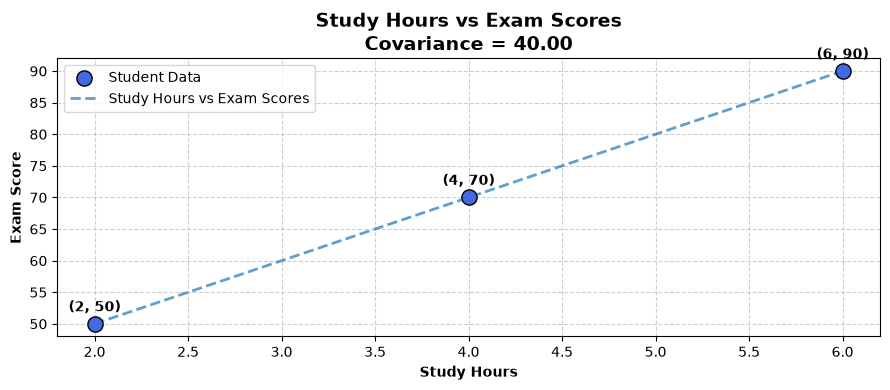

In [17]:
study_hours = np.array([2,4,6])
exam_scores = np.array([50,70,90])
n = len(study_hours)

mean_x = sum(study_hours) / n
mean_y = sum(exam_scores) / n

dev_x = [x - mean_x for x in study_hours]
dev_y = [y - mean_y for y in exam_scores]

prod_dev = [dx * dy for dx, dy in zip(dev_x, dev_y)]
cov_python = sum(prod_dev) / (n - 1)

cov_matrix_numpy = np.cov(study_hours, exam_scores,rowvar=False,ddof=1)
cov_numpy = cov_matrix_numpy[0,1]

print(f"plain python covariance: {cov_python:.2f}")
print(f"numpy np.cov matrix:\n {cov_matrix_numpy}")
print(f"numpy covariance: (x,y): {cov_numpy:.2f}\n")


# Graphical representation of covariance

plt.figure(figsize=(9, 4))

plt.scatter(
    study_hours,
    exam_scores,
    color='royalblue',
    s=120,
    edgecolor='black',
    zorder=3,
    label='Student Data'
)

# Connect the observations
plt.plot(
    study_hours,
    exam_scores,
    linestyle='--',
    linewidth=2,
    alpha=0.7,
    label='Study Hours vs Exam Scores'
)

# Add value labels to each point
for x, y in zip(study_hours, exam_scores):
    plt.text(
        x,
        y + 2,
        f"({x}, {y})",
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

plt.xlabel("Study Hours", fontweight='bold')
plt.ylabel("Exam Score", fontweight='bold')

plt.title(
    f"Study Hours vs Exam Scores\nCovariance = {cov_numpy:.2f}",
    fontsize=14,
    fontweight='bold'
)

plt.grid(
    True,
    linestyle='--',
    alpha=0.6
)

plt.legend()
plt.tight_layout()
plt.show()


# 2. Pearson Correlation Coefficient(np.corrcoet)

Plain Python Pearson r: 1.0000
NumPy np.corrcoef r:   1.0000
Pandas Series corr r:  1.0000

____________________________________________________________
   Hours  Scores
0      2      50
1      4      70
2      6      90
____________________________________________________________
        count  mean   std   min   25%   50%   75%   max
Hours     3.0   4.0   2.0   2.0   3.0   4.0   5.0   6.0
Scores    3.0  70.0  20.0  50.0  60.0  70.0  80.0  90.0


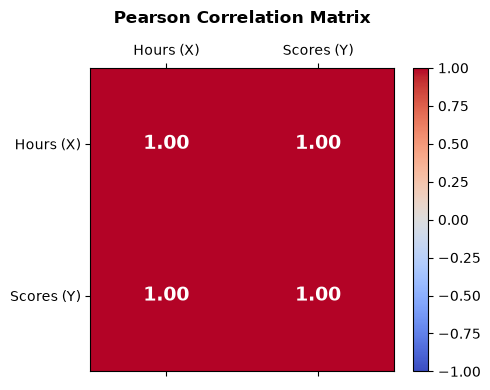

In [18]:
# --- 1. PLAIN PYTHON IMPLEMENTATION ---
var_x = sum((x - mean_x) ** 2 for x in study_hours) / (n - 1)
var_y = sum((y - mean_y) ** 2 for y in exam_scores) / (n - 1)
std_x = math.sqrt(var_x)
std_y = math.sqrt(var_y)

r_python = cov_python / (std_x * std_y)

# --- 2. NUMPY & PANDAS IMPLEMENTATIONS ---
r_numpy_matrix = np.corrcoef(study_hours, exam_scores)
r_numpy = r_numpy_matrix[0, 1]

df = pd.DataFrame({'Hours': study_hours, 'Scores': exam_scores})
r_pandas = df['Hours'].corr(df['Scores'])

print(f"Plain Python Pearson r: {r_python:.4f}")
print(f"NumPy np.corrcoef r:   {r_numpy:.4f}")
print(f"Pandas Series corr r:  {r_pandas:.4f}\n")
print("_" * 60)
print(df)
print("_" * 60)
print(df.describe().T)


# --- 3. VISUAL HEATMAP REPRESENTATION ---
fig, ax = plt.subplots(figsize=(5, 4))
cax = ax.matshow(r_numpy_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{r_numpy_matrix[i, j]:.2f}", ha='center', va='center',
                color='white' if abs(r_numpy_matrix[i, j]) > 0.5 else 'black', fontweight='bold', fontsize=14)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Hours (X)', 'Scores (Y)'])
ax.set_yticklabels(['Hours (X)', 'Scores (Y)'])
ax.set_title('Pearson Correlation Matrix', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 3. Directional Patterns & Non-Linear Limitations

1. Positive Linear r:   0.9746
2. Negative Linear r:   -0.9714
3. Uncorrelated Noise r: -0.1580
4. Quadratic Curve r:    -0.0041 (Near 0 despite direct functional dependency!)



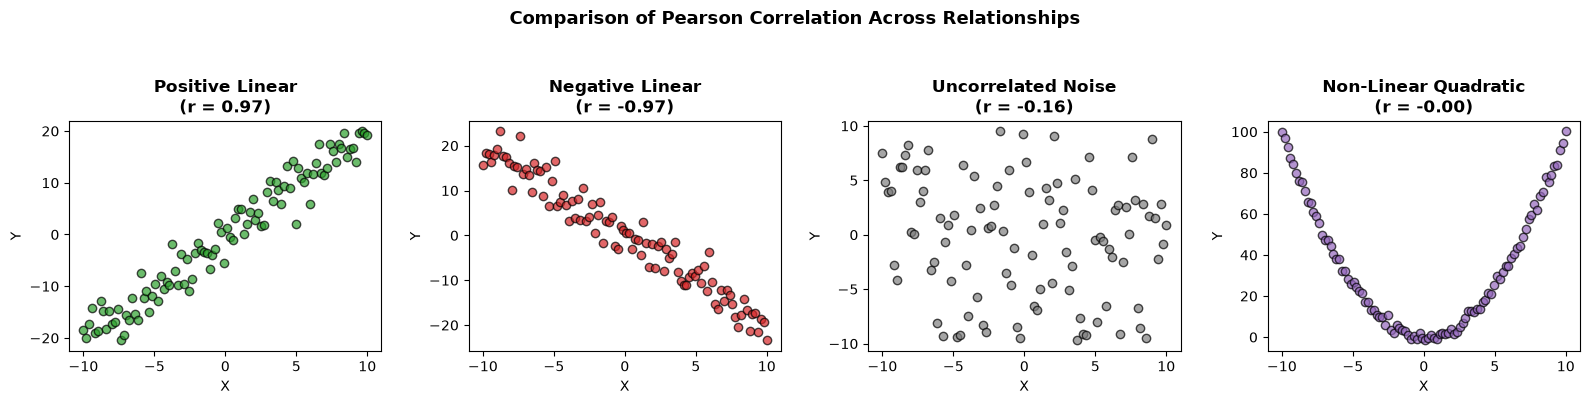

In [19]:
# --- 1. DATASET GENERATION ---
np.random.seed(42)
n_pts = 100

x_p = np.linspace(-10, 10, n_pts)
y_p = 2 * x_p + np.random.normal(0, 3, n_pts)       # Positive Linear
y_n = -2 * x_p + np.random.normal(0, 3, n_pts)      # Negative Linear
y_u = np.random.uniform(-10, 10, n_pts)             # Random Uncorrelated
y_q = x_p**2 + np.random.normal(0, 2, n_pts)         # Quadratic Non-Linear

# Compute correlations
r_p = np.corrcoef(x_p, y_p)[0, 1] # p stands for positive linear correlation
r_n = np.corrcoef(x_p, y_n)[0, 1] # n stands for negative linear correlation
r_u = np.corrcoef(x_p, y_u)[0, 1] # u stands for uncorrelated 
r_q = np.corrcoef(x_p, y_q)[0, 1] # q stands for quadratic non-linear correlation

print(f"1. Positive Linear r:   {r_p:.4f}")
print(f"2. Negative Linear r:   {r_n:.4f}")
print(f"3. Uncorrelated Noise r: {r_u:.4f}")
print(f"4. Quadratic Curve r:    {r_q:.4f} (Near 0 despite direct functional dependency!)\n")


# --- 2. MULTI-PANEL VISUALIZATION ---
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))

axes[0].scatter(x_p, y_p, color='#2ca02c', alpha=0.7, edgecolors='k')
axes[0].set_title(f'Positive Linear\n(r = {r_p:.2f})', fontweight='bold')

axes[1].scatter(x_p, y_n, color='#d62728', alpha=0.7, edgecolors='k')
axes[1].set_title(f'Negative Linear\n(r = {r_n:.2f})', fontweight='bold')

axes[2].scatter(x_p, y_u, color='#7f7f7f', alpha=0.7, edgecolors='k')
axes[2].set_title(f'Uncorrelated Noise\n(r = {r_u:.2f})', fontweight='bold')

axes[3].scatter(x_p, y_q, color='#9467bd', alpha=0.7, edgecolors='k')
axes[3].set_title(f'Non-Linear Quadratic\n(r = {r_q:.2f})', fontweight='bold')

for ax in axes:
    ax.set_xlabel('X')
    ax.set_ylabel('Y')

plt.suptitle('Comparison of Pearson Correlation Across Relationships', fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()